# 2. Convergence: mesh cutoff and k-points

Two numerical parameters control the accuracy of every calculation and must be checked for every new system:
the **mesh cutoff**, which sets the fineness of the real-space mesh, and the **k-point grid**, which samples
the Brillouin zone. (The third one, the basis set, is the subject of tutorial 7.)

**You will learn** to run series of calculations from Python, to judge convergence of energies, forces and
pressure, and to recognise the *egg-box effect*.

Run time: about two minutes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import jax_siesta as js

PSEUDOS = Path("../../examples/pseudos").resolve()
plt.rcParams["figure.dpi"] = 90


def silicon(a=5.47, shift=(0.0, 0.0, 0.0), delta=0.0):
    """Diamond-structure silicon; `shift` moves both atoms rigidly, `delta` displaces the second atom (fractional)."""
    cell = a * np.array([[0.0, 0.5, 0.5], [0.5, 0.0, 0.5], [0.5, 0.5, 0.0]])
    frac = np.array([[0.0, 0.0, 0.0], [0.25, 0.25, 0.25 + delta]]) + np.asarray(shift)
    return js.make_structure(cell, ["Si", "Si"], frac, fractional=True)

We use a silicon crystal with the second atom displaced, so that there are non-zero forces to converge, and
build one calculation that the loops below will vary. `use_symmetry=True` keeps the number of k-points small.

In [2]:
calc = js.Calculation.from_structure(
    silicon(delta=0.01), PSEUDOS, basis="DZP", k_grid=(4, 4, 4),
    xc_functional="PBE", mesh_cutoff_ry=150.0, use_symmetry=True,
)

## Mesh cutoff

The density, the Hartree potential and the exchange-correlation potential live on a uniform mesh. The
`MeshCutoff` is the kinetic energy of the shortest wavelength the mesh can represent; the program picks the
smallest mesh that reaches it, so the cutoff obtained is usually a little higher than requested.

In [3]:
cutoffs = [60, 100, 150, 200, 300, 400]
rows = []
for cutoff in cutoffs:
    r = calc.with_config(mesh_cutoff_ry=float(cutoff)).run()
    rows.append((cutoff, r.mesh_shape[0], r.energy_ev, r.forces_ev_ang[1, 2], r.pressure_gpa))
    print(f"{cutoff:4d} Ry  mesh {r.mesh_shape}  E = {r.energy_ev:.5f} eV  Fz = {r.forces_ev_ang[1, 2]:8.5f} eV/Ang  "
          f"P = {r.pressure_gpa:7.3f} GPa")
rows = np.array(rows)

  60 Ry  mesh (16, 16, 16)  E = -229.89700 eV  Fz =  0.05213 eV/Ang  P =  -0.051 GPa


 100 Ry  mesh (20, 20, 20)  E = -229.89806 eV  Fz =  0.03053 eV/Ang  P =  -0.169 GPa


 150 Ry  mesh (24, 24, 24)  E = -229.89890 eV  Fz =  0.05116 eV/Ang  P =   0.314 GPa


 200 Ry  mesh (30, 30, 30)  E = -229.89842 eV  Fz =  0.02709 eV/Ang  P =   0.189 GPa


 300 Ry  mesh (36, 36, 36)  E = -229.89856 eV  Fz =  0.03164 eV/Ang  P =   0.218 GPa


 400 Ry  mesh (40, 40, 40)  E = -229.89829 eV  Fz =  0.03062 eV/Ang  P =   0.039 GPa


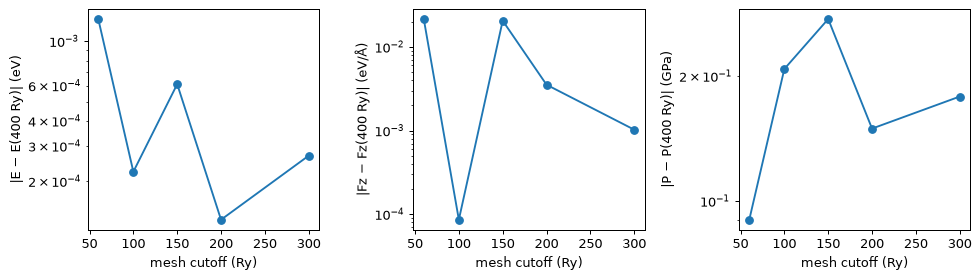

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
ref = rows[-1]
for ax, col, label in zip(axes, (2, 3, 4), ("|E − E(400 Ry)| (eV)", "|Fz − Fz(400 Ry)| (eV/Å)", "|P − P(400 Ry)| (GPa)")):
    ax.semilogy(rows[:-1, 0], np.abs(rows[:-1, col] - ref[col]), "o-")
    ax.set_xlabel("mesh cutoff (Ry)")
    ax.set_ylabel(label)
fig.tight_layout()

The convergence is not monotonic: the error depends on how the atoms sit relative to the mesh points. The
total energy is within a meV of its limit from 100 Ry on, but the force still changes by 0.02 eV/Ang between
150 and 200 Ry and settles only around 300 Ry, and the pressure moves by 0.2 GPa even between 300 and 400 Ry.
These PseudoDojo pseudopotentials are fairly hard (norm-conserving with a core correction), so they need a
finer mesh than the softer pseudopotentials traditionally used with SIESTA.

## The egg-box effect

In free space the energy cannot depend on where the crystal sits. On a mesh it does, slightly: moving all
atoms rigidly changes the energy with the period of the mesh, like an egg rolling over an egg box. The
amplitude of that ripple measures the quality of the mesh, and its slope is a spurious force.

60 Ry: egg-box amplitude 3.749 meV per cell


150 Ry: egg-box amplitude 0.879 meV per cell


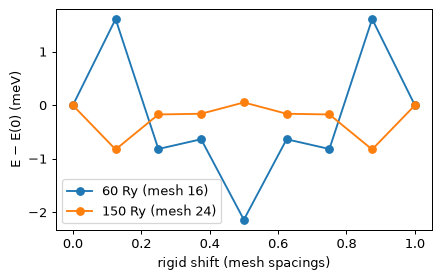

In [5]:
perfect = calc.with_structure(silicon())
shifts = np.linspace(0.0, 1.0, 9)  # in units of one mesh spacing along the first lattice vector
fig, ax = plt.subplots(figsize=(5, 3.2))
for cutoff in (60, 150):
    c = perfect.with_config(mesh_cutoff_ry=float(cutoff))
    n1 = c.run().mesh_shape[0]
    energies = [c.with_structure(silicon(shift=(s / n1, 0.0, 0.0))).run().energy_ev for s in shifts]
    ripple = (np.array(energies) - energies[0]) * 1000.0
    ax.plot(shifts, ripple, "o-", label=f"{cutoff} Ry (mesh {n1})")
    print(f"{cutoff} Ry: egg-box amplitude {np.ptp(ripple):.3f} meV per cell")
ax.set_xlabel("rigid shift (mesh spacings)")
ax.set_ylabel("E − E(0) (meV)")
ax.legend()
fig.tight_layout()

The ripple is periodic with the mesh spacing and falls quickly with the cutoff. If a calculation shows a net
force on the whole cell, or noisy forces during a geometry scan, the mesh is too coarse.

## k-points

For a periodic system, quantities are averages over the Brillouin zone, replaced by a sum over a
Monkhorst-Pack grid. Insulators such as silicon converge quickly; metals need denser grids and a smearing of
the occupations (`ElectronicTemperature`).

In [6]:
grids = [2, 3, 4, 6, 8]
krows = []
for n in grids:
    r = calc.with_config(k_grid=(n, n, n)).run()
    krows.append((n, r.kmesh.n_k, r.energy_ev, r.forces_ev_ang[1, 2], r.pressure_gpa))
    print(f"{n} x {n} x {n}: {r.kmesh.n_k:3d} irreducible k-points  E = {r.energy_ev:.5f} eV  "
          f"Fz = {r.forces_ev_ang[1, 2]:8.5f} eV/Ang  P = {r.pressure_gpa:7.3f} GPa")
krows = np.array(krows)

2 x 2 x 2:   6 irreducible k-points  E = -227.51696 eV  Fz =  0.05591 eV/Ang  P =   7.551 GPa


3 x 3 x 3:  10 irreducible k-points  E = -229.46727 eV  Fz =  0.05246 eV/Ang  P =   1.594 GPa


4 x 4 x 4:  24 irreducible k-points  E = -229.89890 eV  Fz =  0.05116 eV/Ang  P =   0.314 GPa


6 x 6 x 6:  68 irreducible k-points  E = -230.06118 eV  Fz =  0.05009 eV/Ang  P =  -0.194 GPa


8 x 8 x 8: 150 irreducible k-points  E = -230.08067 eV  Fz =  0.04986 eV/Ang  P =  -0.254 GPa


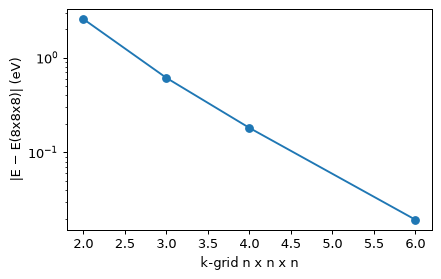

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogy(krows[:-1, 0], np.abs(krows[:-1, 2] - krows[-1, 2]), "o-")
ax.set_xlabel("k-grid n x n x n")
ax.set_ylabel("|E − E(8x8x8)| (eV)")
fig.tight_layout()

## What to take away

* Converge the quantity you need, not only the total energy: energy *differences*, forces and especially the
  pressure converge at different rates.
* Keep the parameters fixed when comparing calculations (same mesh cutoff and k-grid for all volumes of an
  equation of state, for instance).
* The mesh cutoff needed is a property of the pseudopotentials and basis, the k-grid of the cell size and of
  whether the system is a metal.

## Exercises

1. Which mesh cutoff and k-grid converge the *pressure* of this crystal to 0.1 GPa? Is that the same as for
   the energy to 1 meV?
2. Repeat the egg-box scan at 300 Ry. By what factor does the amplitude fall between 150 and 300 Ry?
3. Shifted grids: run the *perfect* crystal without symmetry and with `k_shift=(0.5, 0.5, 0.5)`. The forces
   are no longer zero. Why? (Hint: does the shifted grid have the symmetry of the fcc reciprocal lattice?)
4. The time per calculation is in `results.timings`. Plot the SCF time against the mesh cutoff and against
   the number of k-points.